# Lab 23: Synthetic Recovery and Identifiability Testing

This lab fits the reference Bayesian MMM from Lab 15 to the Sedge Shoes national aggregate and compares its recovered per-channel ROAS to the `GROUND_TRUTH` ROAS baked into the Sedge generator.
It then goes further and stress-tests identifiability: it makes two channels' spend collinear and refits, to show what happens to a model's estimates when the data cannot tell two channels apart.
Recovering the exact ground truth is not the point of a synthetic-recovery exercise; understanding when and why recovery is close, and when it structurally cannot be, is.
It accompanies Chapter 23 of the book Marketing Mix Modelling.

In [1]:
import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pymc as pm

from mmm_book import RANDOM_SEED
from mmm_book.plotting import mmm_style
from mmm_book.reference import REVENUE_SCALE, build_features, national_aggregate, reference_model
from mmm_book.sedge import CHANNELS, GROUND_TRUTH, TV_COST_PER_GRP, generate_sedge

mmm_style()


def check(idata):
    n_divergent = int(idata.sample_stats["diverging"].sum())
    r_hat = float(az.summary(idata, kind="diagnostics")["r_hat"].max())
    print(f"divergent transitions: {n_divergent}, largest r_hat: {r_hat:.3f}")


_MEDIA_COL = {
    "tv": "tv_grps",
    "search": "search_spend",
    "meta": "meta_spend",
    "youtube": "youtube_spend",
    "ooh": "ooh_spend",
}

## Fitting the reference model

This reuses the shared national-aggregate reference model from `mmm_book.reference`, the model Lab 15 builds with the priors Lab 17 chooses, as used in Labs 18 and 21.

## Sampling

Sampling uses the settings every lab uses: four chains of 1,000 draws after 1,000 warm-up steps, with a target acceptance rate of 0.95.
The cell checks that this fit samples cleanly (no divergences, every `r_hat` at or below 1.01); Lab 18 shows what goes wrong with fewer, shorter chains.
The model fixes each channel's adstock and saturation at the values the data were built with, so only the channel scales, baseline and controls are estimated; the case-study notebooks estimate the transforms as well.

In [2]:
df = generate_sedge()
nat = national_aggregate(df)
model = reference_model(nat)

with model:
    idata = pm.sample(
        draws=1000,
        tune=1000,
        chains=4,
        cores=1,
        target_accept=0.95,
        random_seed=RANDOM_SEED,
        progressbar=False,
    )

check(idata)

Initializing NUTS using jitter+adapt_diag...


Sequential sampling (4 chains in 1 job)


NUTS: [intercept, trend, season_a, season_b, omega_launch, delta_promo, gamma_log_price, gamma_distribution, gamma_stock, gamma_temperature, gamma_rainfall, gamma_category, beta_tv, beta_search, beta_meta, beta_youtube, beta_ooh, sigma]


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 25 seconds.


divergent transitions: 0, largest r_hat: 1.004


## Step 1 - recovered vs ground-truth ROAS

`GROUND_TRUTH` is baked into the Sedge generator by construction (see the `mmm_book.sedge` module docstring): each channel's contribution shape is scaled so that `contribution.sum() / spend.sum()` equals `GROUND_TRUTH[channel]` exactly, in the per-region data used to generate the panel.
The model fit here uses the *national aggregate* built by `national_aggregate`, and `build_features` computes each channel's saturation half-point from the *national* adstocked series (a fixed multiple, `HALF_MULT`, of its mean), not from any individual region's own series.
Both of those differ from how the data was actually generated, so an exact match between recovered and ground-truth ROAS is not expected, only an approximation, and with the realistic Sedge data the gap can be large.
For each posterior draw, a channel's recovered contribution is its beta multiplied by its feature and rescaled by `REVENUE_SCALE`; dividing by that channel's spend gives a recovered ROAS (TV's GRPs are converted to a spend equivalent via `TV_COST_PER_GRP`, and Search's ROAS is quoted on total Search spend, as in the book).
The table shows the posterior mean and the 90 per cent interval.

In [3]:
feat = build_features(nat)

spend_equiv = {
    ch: (
        nat["tv_grps"].to_numpy(dtype=float) * TV_COST_PER_GRP
        if ch == "tv"
        else nat[_MEDIA_COL[ch]].to_numpy(dtype=float)
    )
    for ch in CHANNELS
}

recovered_roas = {}
recovered_interval = {}
for ch in CHANNELS:
    beta_draws = idata.posterior[f"beta_{ch}"].to_numpy().reshape(-1)
    roas_draws = beta_draws * feat[ch].sum() * REVENUE_SCALE / spend_equiv[ch].sum()
    recovered_roas[ch] = float(roas_draws.mean())
    recovered_interval[ch] = np.percentile(roas_draws, [5, 95])

print(f"{'channel':<10}{'recovered':>12}{'90% interval':>16}{'ground truth':>15}")
for ch in CHANNELS:
    lo, hi = recovered_interval[ch]
    interval = f"{lo:.2f}-{hi:.2f}"
    print(f"{ch:<10}{recovered_roas[ch]:>12.2f}{interval:>16}{GROUND_TRUTH[ch]:>15.2f}")

channel      recovered    90% interval   ground truth
tv                2.39       2.18-2.60           2.40
search            3.10       0.74-5.54           2.70
meta              3.07       1.61-4.34           1.75
youtube           1.02       0.09-2.45           2.00
ooh               1.50       0.15-3.34           1.50


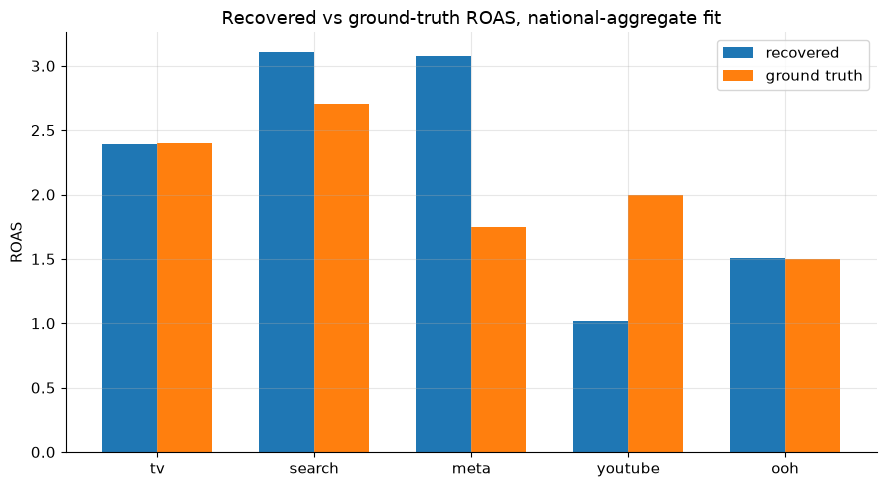

In [4]:
x = np.arange(len(CHANNELS))
width = 0.35

fig, ax = plt.subplots()
ax.bar(x - width / 2, [recovered_roas[ch] for ch in CHANNELS], width, label="recovered")
ax.bar(x + width / 2, [GROUND_TRUTH[ch] for ch in CHANNELS], width, label="ground truth")
ax.set_xticks(x)
ax.set_xticklabels(CHANNELS)
ax.set_ylabel("ROAS")
ax.set_title("Recovered vs ground-truth ROAS, national-aggregate fit")
ax.legend()
fig.tight_layout()

## Step 2 - an identifiability stress test

National aggregation and a data-dependent saturation half already keep recovery from being exact, but a sharper failure mode is identifiability: when two channels' spend moves together, no amount of data lets a model tell which one is driving revenue.
To demonstrate this, `meta_spend` and `youtube_spend` are both replaced by their shared average, a deliberately extreme case of two channels being planned and spent together.
The two channels keep their own adstock alpha and Hill slope, so their *features* end up highly correlated rather than numerically identical.

In [5]:
nat_collinear = nat.copy()
shared_spend = (nat_collinear["meta_spend"] + nat_collinear["youtube_spend"]) / 2.0
nat_collinear["meta_spend"] = shared_spend
nat_collinear["youtube_spend"] = shared_spend

feat_collinear = build_features(nat_collinear)
feature_corr = float(np.corrcoef(feat_collinear["meta"], feat_collinear["youtube"])[0, 1])
feature_corr_recorded = float(np.corrcoef(feat["meta"], feat["youtube"])[0, 1])
print(f"correlation between meta and youtube features as recorded: {feature_corr_recorded:.3f}")
print(f"correlation between meta and youtube features after collinearity: {feature_corr:.3f}")

correlation between meta and youtube features as recorded: 0.840
correlation between meta and youtube features after collinearity: 0.989


## Refitting on the collinear variant

Sampling settings are the same as above.

In [6]:
model_collinear = reference_model(nat_collinear)
with model_collinear:
    idata_collinear = pm.sample(
        draws=1000,
        tune=1000,
        chains=4,
        cores=1,
        target_accept=0.95,
        random_seed=RANDOM_SEED,
        progressbar=False,
    )

check(idata_collinear)

Initializing NUTS using jitter+adapt_diag...


Sequential sampling (4 chains in 1 job)


NUTS: [intercept, trend, season_a, season_b, omega_launch, delta_promo, gamma_log_price, gamma_distribution, gamma_stock, gamma_temperature, gamma_rainfall, gamma_category, beta_tv, beta_search, beta_meta, beta_youtube, beta_ooh, sigma]


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 28 seconds.


divergent transitions: 0, largest r_hat: 1.005


## Step 3 - individual estimates swap, the sum does not

For each posterior draw, `beta_meta` and `beta_youtube` imply a per-channel ROAS.
The fraction of draws where meta's implied ROAS exceeds youtube's is a direct measure of how confidently the model can tell the two channels apart: close to 0 or 1 means a clear, consistent ordering, close to 0.5 means the model has no idea which channel is better and the answer is effectively a coin flip.
The combined ROAS, meta plus youtube contribution over meta plus youtube spend, is compared alongside it, since that combined quantity is what the data can still identify even when the individual split cannot.

In [7]:
def channel_roas_draws(nat_, idata_, ch):
    feat_ = build_features(nat_)
    beta_draws = idata_.posterior[f"beta_{ch}"].values.flatten()
    contribution_total = float(feat_[ch].sum()) * REVENUE_SCALE
    spend_total = float(nat_[_MEDIA_COL[ch]].to_numpy(dtype=float).sum())
    return beta_draws * contribution_total / spend_total


roas_meta_base = channel_roas_draws(nat, idata, "meta")
roas_youtube_base = channel_roas_draws(nat, idata, "youtube")
roas_meta_col = channel_roas_draws(nat_collinear, idata_collinear, "meta")
roas_youtube_col = channel_roas_draws(nat_collinear, idata_collinear, "youtube")

for label, rm, ry, n_ in [
    ("independent-spend fit", roas_meta_base, roas_youtube_base, nat),
    ("collinear (shared-spend) fit", roas_meta_col, roas_youtube_col, nat_collinear),
]:
    spend_m, spend_y = float(n_["meta_spend"].sum()), float(n_["youtube_spend"].sum())
    combined = (rm * spend_m + ry * spend_y) / (spend_m + spend_y)
    p_meta_higher = float((rm > ry).mean())
    print(
        f"{label}:\n"
        f"  meta ROAS mean={rm.mean():.2f}, youtube ROAS mean={ry.mean():.2f}, "
        f"P(meta > youtube)={p_meta_higher:.2f}\n"
        f"  combined ROAS mean={combined.mean():.2f}, sd={combined.std():.2f}"
    )

independent-spend fit:
  meta ROAS mean=3.07, youtube ROAS mean=1.02, P(meta > youtube)=0.91
  combined ROAS mean=2.36, sd=0.41
collinear (shared-spend) fit:
  meta ROAS mean=2.03, youtube ROAS mean=1.87, P(meta > youtube)=0.48
  combined ROAS mean=1.95, sd=0.41


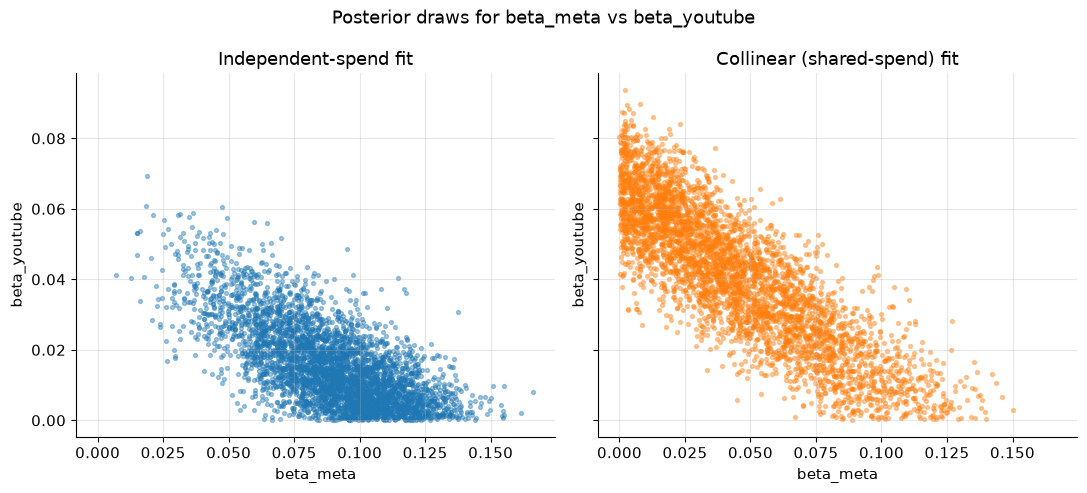

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharex=True, sharey=True)

bm_base = idata.posterior["beta_meta"].values.flatten()
by_base = idata.posterior["beta_youtube"].values.flatten()
bm_col = idata_collinear.posterior["beta_meta"].values.flatten()
by_col = idata_collinear.posterior["beta_youtube"].values.flatten()

axes[0].scatter(bm_base, by_base, s=8, alpha=0.4)
axes[0].set_title("Independent-spend fit")
axes[1].scatter(bm_col, by_col, s=8, alpha=0.4, color="C1")
axes[1].set_title("Collinear (shared-spend) fit")
for ax in axes:
    ax.set_xlabel("beta_meta")
    ax.set_ylabel("beta_youtube")
fig.suptitle("Posterior draws for beta_meta vs beta_youtube")
fig.tight_layout()

## Takeaway

Recovery on the national aggregate is approximate, and for some channels poor, even when the channels' spend is left as Sedge recorded it.
Chapter 23's table shows close recovery when channels move independently; Sedge's channels do not, and this model sees them only through the national total.
Aggregating away the regional variation, and computing each channel's saturation half-point from the national series rather than from the regional ones the data were generated with, both bias the estimates, and a single synthetic draw adds noise on top.
In this run Television (2.39 against 2.4) and OOH (1.50 against 1.5) land on the ledger, OOH with a very wide interval, Paid Search is somewhat high (3.10 against 2.7), and Meta and YouTube miss in opposite directions (3.07 against 1.75, and 1.02 against 2.0).
Meta and YouTube share a paid-social budget, so their features are correlated (0.84 even in the independent-spend fit) and the split between them is unreliable here too, while the pair taken together is better known.
None of this is sampler failure: every fit passed its diagnostics.

The collinearity stress test is the sharper lesson.
Once Meta and YouTube spend move together, the share of posterior draws favouring Meta over YouTube falls from 0.91 to 0.48, a coin flip, and the scatter of `beta_meta` against `beta_youtube` stretches into a ridge along which one channel's credit trades off against the other's.
The individual means move a long way (Meta from 3.07 to 2.03, YouTube from 1.02 to 1.87), while the combined ROAS keeps the same standard deviation (0.41 in both fits) and its mean moves less, from 2.36 to 1.95: the data can still pin down roughly how much the two channels earned together, not how that credit splits between them.
This is a structural limit, not a modelling mistake: no amount of additional data drawn from the same collinear spend pattern will separate the two channels, because the likelihood does not distinguish them.
The practical response is either to report a combined figure for channels that are planned together, or to break the tie with an outside source of variation, which is exactly what an experiment provides, the subject of Chapter 24 and Lab 24.